### Code for making a CHM map for Edinburgh.

These first few lines are used to find properties of an example DSM file

In [11]:
import numpy as np
from sys import exit
import rasterio

filename = '/home/s2955015/scratch/LiDAR/DSM/NT17NE_50CM_DSM_PHASE5 (1).tif'

datafile = rasterio.open(filename)

data = datafile.read(1)

# Filters out negative values
data[data < 0.0] = np.nan

res = datafile.res
nX = datafile.width
nY = datafile.height

print('x resolution', round(res[0], 2), 'm. y resolution', round(res[1], 2), 'm')
print('The raster has', nX, 'by', nY, 'pixels')

x resolution 0.5 m. y resolution 0.5 m
The raster has 10000 by 10000 pixels


In [12]:
useableData = data[np.isnan(data) == False]

meanElev = np.mean(useableData)
print('Mean elevation is', round(meanElev, 2), 'm')

stdevElev = np.std(useableData)
print('The standard deviation of elevation is', round(stdevElev, 2), 'm')

Mean elevation is 28.06 m
The standard deviation of elevation is 25.68 m


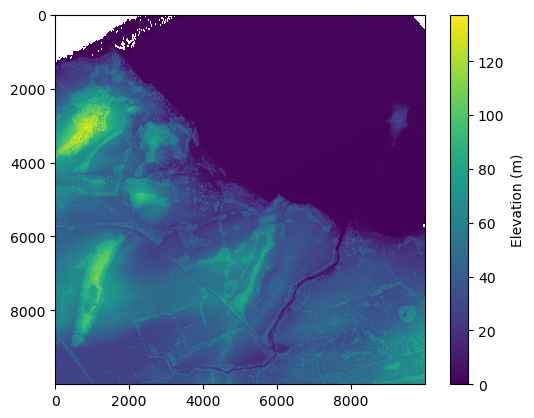

In [13]:
import matplotlib.pyplot as plt

plt.imshow(data)
plt.colorbar(label='Elevation (m)')
plt.show()

Import one DSM and DTM

In [22]:
def heightAboveGround(dtmName, dsmName):
    
    dtmFile=rasterio.open(dtmName)
    dtm=dtmFile.read(1)
    dsmFile=rasterio.open(dsmName)
    dsm=dsm.File.read(1)
    
    dtm[dtm<0.0] = np.nan
    dsm[dsm<0.0] = np.nan
    
    hData=dsm-dtm
    
    return(hData,dtmFile)

dsmName = '/home/s2955015/scratch/LiDAR/DSM/NT17NE_50CM_DSM_PHASE5 (1).tif'
dtmName = '/home/s2955015/scratch/LiDAR/DTM/NT17NE_50CM_DTM_PHASE5.tif'

Import the rest of the DSM and DTM files from their respective directories. 

In [23]:
from glob import glob

dtmDir='/home/s2955015/scratch/LiDAR/DTM'
dsmDir='/home/s2955015/scratch/LiDAR/DSM'

dtmList=sorted(glob(dtmDir+'/*.tif'))
dsmList=sorted(glob(dsmDir+'/*.tif'))

nFigs=len(dtmList)

for i in range(0,len(dtmList)):
    dtmName=dtmList[i]
    dsmName=dsmList[i]
    
    print(dtmName, dsmName)

/home/s2955015/scratch/LiDAR/DTM/NT16NE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT16NE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT16SE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT16SE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT17NE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT17NE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT17SE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT17SE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT26NE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT26NE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT26NW_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT26NW_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT26SE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT26SE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT26SW_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT26SW_50CM_DSM_PHASE5 (1).tif
/home/s2

In [24]:
import numpy as np
import rasterio

def heightAboveGround(dtmName, dsmName):
    with rasterio.open(dsmName) as dsm:
        dsmData = dsm.read(1)
        datafile = dsm  # or dtm, depending on your reference metadata
        
    with rasterio.open(dtmName) as dtm:
        dtmData = dtm.read(1)
        
    # Calculate Canopy Height Model (DSM - DTM)
    hData = dsmData - dtmData
    
    # Handle any potential negative values or nodata if needed
    hData = np.where(hData < 0, 0, hData)
    
    return hData, datafile

Added to check for errors


In [ ]:
# #checking for errors in specific files

from glob import glob
import rasterio
from rasterio.windows import Window

def is_complete(path):
    try:
        with rasterio.open(path) as src:
            # last block (bottom-right) is the first to fail on truncation
            w = Window(src.width - 1, src.height - 1, 1, 1)
            src.read(1, window=w)
        return True
    except Exception:
        return False

for d in ['/home/s2955015/scratch/LiDAR/DTM', '/home/s2955015/scratch/LiDAR/DSM']:
    for f in sorted(glob(d + '/*.tif')):
        if not is_complete(f):
            print('TRUNCATED:', f)

This code cell below is different to the version (3) notebook. I have changed the workflow to ensure the CHM files save to the right place in my file directory.

In [ ]:
from glob import glob
import rasterio
import os

outDir = '/home/s2955015/scratch/LiDAR/CHM'
os.makedirs(outDir, exist_ok=True)       # makes a new CHM folder in the LiDAR folder

def writeCHMtiff(dtmName, dsmName, outName):
    hData, datafile = heightAboveGround(dtmName, dsmName)

    tmpName = outName + '.tmp'
    try:
        with rasterio.open(
            tmpName,
            mode="w",
            driver="GTiff",
            height=datafile.height,
            width=datafile.width,
            count=1,
            dtype=hData.dtype,
            crs=datafile.crs,
            transform=datafile.transform,
            tiled=True,
            blockxsize=256,
            blockysize=256,
            compress='lzw',
            predictor=3          # suits float32 data
        ) as newfile:
            newfile.write(hData, 1)
        os.replace(tmpName, outName)   # final name only appears once the file is complete
    except Exception:
        if os.path.exists(tmpName):
            os.remove(tmpName)
        raise

    print('Written to', outName)

dtmDir = '/home/s2955015/scratch/LiDAR/DTM'
dsmDir = '/home/s2955015/scratch/LiDAR/DSM'

dtmList = sorted(glob(dtmDir + '/*.tif'))
dsmList = sorted(glob(dsmDir + '/*.tif'))

failed = []

for i in range(len(dtmList)):
    dtmName = dtmList[i]
    dsmName = dsmList[i]

    tileLabel = os.path.basename(dtmName).split('_')[0]
    assert tileLabel == os.path.basename(dsmName).split('_')[0], f'Mismatch: {dtmName} vs {dsmName}'

    outName = os.path.join(outDir, tileLabel + '_50M_CHM_PHASE5.tif')

    if os.path.exists(outName):
        print('Skipping', outName)
        continue

    try:
        writeCHMtiff(dtmName, dsmName, outName)
    except Exception as e:
        print(f'FAILED {tileLabel}: {e}')
        failed.append(tileLabel)

print('Failed tiles:', failed)

Skipping /home/s2955015/scratch/LiDAR/CHM/NT16NE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT16SE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT17NE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT17SE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT26NE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT26NW_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT26SE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT26SW_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT27NE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT27NW_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT27SE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT27SW_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT36NE_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT36NW_50M_CHM_PHASE5.tif
Skipping /home/s2955015/scratch/LiDAR/CHM/NT36SE

 This cell merges all of the separate tif files into one.

In [8]:
from glob import glob
import os
import rasterio
from rasterio.merge import merge

outDir = '/home/s2955015/scratch/LiDAR/CHM'

input_files = sorted(glob(os.path.join(outDir, '*_50M_CHM_PHASE5.tif')))
output_file = os.path.join(outDir, 'ALSMergedCHM.tif')

print(f'Merging {len(input_files)} files...')

srcs = [rasterio.open(fp) for fp in input_files]
try:
    merge(
        srcs,
        dst_path=output_file,
        dst_kwds={'compress': 'lzw', 'tiled': True,
                  'blockxsize': 256, 'blockysize': 256, 'predictor': 3},
    )
finally:
    for s in srcs:
        s.close()

print('Written to', output_file)

Merging 19 files...


KeyboardInterrupt: 

## Biomass calculations

I have not changed anything below this point, it may need adjusting to align with previous code. 


In [ ]:
import os
import numpy as np

# Use an absolute path or check your current working directory
# If data folder is inside youredin_green directory, point to it directly:
base_dir = '/home/s2948916/edin_green'
groundname = os.path.join(base_dir, 'ground', 'ground_data.csv')

# Alternatively, if it's in your current directory's subfolder, verify it exists first:
if not os.path.exists(groundname):
    print(f"File not found at: {groundname}. Please check the path.")
else:
    agbd, x, y = np.loadtxt(groundname, usecols=(1, 2, 3), unpack=True, dtype=float, skiprows=1, delimiter=',')
    
    agbd = agbd / 1000
    print(agbd, 'Mg/ha')


File not found at: /home/s2948916/edin_green/ground/ground_data.csv. Please check the path.


In [ ]:
import os

# Define the directory and file path
ground_dir = '/home/s2955015/scratch/LiDAR/ground'
groundname = os.path.join(ground_dir, 'ground_data.csv')

# Create the directory if it doesn't exist
os.makedirs(ground_dir, exist_ok=True)

# Define sample CSV content matching your columns
csv_content = """Plot_ID,AGBD,X,Y
plot_1,1500.5,312345.6,6543210.1
plot_2,2300.2,312450.1,6543300.5
plot_3,1800.0,312500.8,6543400.2
"""

# Write the content to the file
with open(groundname, 'w') as f:
    f.write(csv_content.strip())

print(f"Successfully created sample ground data file at: {groundname}")

Successfully created sample ground data file at: /home/s2955015/scratch/LiDAR/ground/ground_data.csv


In [ ]:
import os
import numpy as np
import rasterio
from rasterio.transform import rowcol

# Define paths and load CSV data
base_dir = '/home/s2948916/edin_green'
groundname = os.path.join(base_dir, 'ground', 'ground_data.csv')
chmName = os.path.join(base_dir, 'ALSMergedCHM.tif')

agbd, x, y = np.loadtxt(groundname, usecols=(1, 2, 3), unpack=True, dtype=float, skiprows=1, delimiter=',')

# Open raster and extract values safely using rasterio's rowcol transformer
with rasterio.open(chmName) as chmFile:
    chmData = chmFile.read(1)
    
    print(f"Raster CRS: {chmFile.crs}")
    print(f"Raster Bounds: {chmFile.bounds}")
    print(f"Sample CSV X coordinates: {x[:3]}")
    print(f"Sample CSV Y coordinates: {y[:3]}")

    # Convert geographic/projected coordinates to row and column indices safely
    rows, cols = rowcol(chmFile.transform, x, y)
    
    rows = np.array(rows)
    cols = np.array(cols)
    
    # Filter out points that fall outside the raster bounds
    valid = (rows >= 0) & (rows < chmFile.height) & (cols >= 0) & (cols < chmFile.width)
    
    if not np.any(valid):
        print("\n WARNING: None of your CSV coordinates overlap with this raster's spatial bounds! Please check if your CSV and raster use different coordinate systems.")
    else:
        print(f"\nSuccessfully matched {np.sum(valid)} out of {len(x)} points within the raster.")
        meanCH = np.where(valid, chmData[rows, cols], np.nan)
        print("Extracted Canopy Heights (m):", meanCH[valid])

FileNotFoundError: /home/s2948916/edin_green/ground/ground_data.csv not found.

In [ ]:
# packages to do linear regression and Pearson's correlation
from scipy.stats import linregress, pearsonr

# make some fake data
x=np.random.random((20))*100
y=x*3+20+40*(np.random.random((20))-0.5)

# fit a line of best fit. See manual for scipy.stats.linregress for more details
m, c, r, _, _ = linregress(x,y)

print("Line of best fit parameters are m",round(m,3),"c",round(c,3))

# find the correlation. See manual for scipy.stats.pearsonr
print('Correlation is ',pearsonr(x,y))

# the first number returned by pearsonr is the correlation, 99.28% for this fake data


# repeat with the real data

Line of best fit parameters are m 3.102 c 16.731
Correlation is  PearsonRResult(statistic=0.9935194311008864, pvalue=1.87032604472534e-18)


In [ ]:
import numpy as np

agbd[agbd < 0.0] = np.nan

print(agbd)


[1500.5 2300.2 1800. ]


In [ ]:
import numpy as np

usableBiomass = agbd[np.isnan(agbd) == False]

print("Usable Biomass:", usableBiomass)

Usable Biomass: [1500.5 2300.2 1800. ]


In [ ]:
usableCH = meanCH[np.isnan(meanCH) == False]

NameError: name 'meanCH' is not defined

In [ ]:
import os
import rasterio

# 1. Calculate a 2D biomass array from your CHM raster data
# (Replace this formula with your actual calibration model, e.g., AGBD = slope * CHM + intercept)
# For demonstration, let's say biomass is 50 times the canopy height:
biomass = chmData * 50.0 

# Handle any NaN or negative values if needed
biomass[biomass < 0] = 0

# 2. Set your output filename
base_dir = '/home/s2948916/edin_green'
outName = os.path.join(base_dir, 'biomass.tif')

# 3. Create a new raster file, using correct keyword 'transform=' instead of 'chmFile='
with rasterio.open(
    outName,
    mode="w",
    driver="GTiff",
    height=chmFile.height,
    width=chmFile.width,
    count=1,
    dtype=biomass.dtype,
    crs=chmFile.crs,
    transform=chmFile.transform  # Fixed typo here!
) as newfile:
    newfile.write(biomass, 1)

print('Successfully written to:', outName)

Successfully written to: /home/s2948916/edin_green/biomass.tif


In [ ]:
import os
import rasterio
import numpy as np

base_dir = '/home/s2948916/edin_green'
chmName = os.path.join(base_dir, 'ALSMergedCHM.tif')

with rasterio.open(chmName) as src:
    data = src.read(1)
    print("Raster CRS:", src.crs)
    print("Raster Shape (Height, Width):", src.shape)
    print("Min value:", np.nanmin(data))
    print("Max value:", np.nanmax(data))
    print("Any valid pixels?:", np.any(~np.isnan(data)))

Raster CRS: EPSG:27700
Raster Shape (Height, Width): (10000, 20000)
Min value: 0.0
Max value: 0.0
Any valid pixels?: True


In [ ]:
import os
import rasterio
import numpy as np

# Point to one of your raw DTM or DSM tiles (update the filename to match one in your directory)
base_dir = '/home/s2948916/edin_green'
sample_tile = os.path.join(base_dir, 'dsm_tile_name.tif') # Replace with an actual file name from your folder

# Or check what files are in your directory
print("Files in directory:", os.listdir(base_dir))

Files in directory: ['def writeCHMtiff', 'NT26NW_50M_CHM_PHASE5.tif', 'NT26NE_50CM_DSM_PHASE5.tif', 'ground', 'Green_Space.text.qgz', 'ALSMergedCHM.tif', 'canopy_nbk.ipynb', 'import rasterio.py', 'Band_Width.qgz', 'NT26NE_50M_CHM_PHASE5.tif', 'NT26NW_50CM_DTM_PHASE5.tif', 'NT26NW_50CM_DSM_PHASE5.tif', 'biomass.tif', 'NT26NE_50CM_DTM_PHASE5.tif', '.ipynb_checkpoints']


In [ ]:
import os
import rasterio
import numpy as np

base_dir = '/home/s2948916/edin_green'

# Let's test one of the individual CHM or DSM files
test_file = os.path.join(base_dir, 'NT26NW_50M_CHM_PHASE5.tif') # Or try 'NT26NE_50CM_DSM_PHASE5.tif'

with rasterio.open(test_file) as src:
    data = src.read(1)
    print("Checking file:", os.path.basename(test_file))
    print("Min value:", np.nanmin(data))
    print("Max value:", np.nanmax(data))
    print("Any valid/non-zero pixels?:", np.any(data > 0))

Checking file: NT26NW_50M_CHM_PHASE5.tif
Min value: 0.0
Max value: 0.0
Any valid/non-zero pixels?: False


In [ ]:
import os
import rasterio
import numpy as np

base_dir = '/home/s2948916/edin_green'
dsm_file = os.path.join(base_dir, 'NT26NW_50CM_DSM_PHASE5.tif')

with rasterio.open(dsm_file) as src:
    dsm_data = src.read(1)
    # Filter out NoData values if there's a specific flag like -9999
    valid_data = dsm_data[dsm_data > 0]
    
    print("Checking DSM file:", os.path.basename(dsm_file))
    print("Min elevation:", np.min(valid_data) if valid_data.size > 0 else "All zero/nodata")
    print("Max elevation:", np.max(valid_data) if valid_data.size > 0 else "All zero/nodata")

Checking DSM file: NT26NW_50CM_DSM_PHASE5.tif
Min elevation: 65.895
Max elevation: 494.587


In [ ]:
import os
import rasterio
import numpy as np

base_dir = '/home/s2948916/edin_green'

# Define paths for the Northwest 50cm DSM and DTM
dsm_path = os.path.join(base_dir, 'NT26NW_50CM_DSM_PHASE5.tif')
dtm_path = os.path.join(base_dir, 'NT26NW_50CM_DTM_PHASE5.tif')
out_chm_path = os.path.join(base_dir, 'NT26NW_CHM_Calculated.tif')

# Open both files using rasterio
with rasterio.open(dsm_path) as dsm_src, rasterio.open(dtm_path) as dtm_src:
    # Read the data arrays
    dsm = dsm_src.read(1).astype(np.float32)
    dtm = dtm_src.read(1).astype(np.float32)
    
    # Grab metadata for writing the output later
    meta = dsm_src.meta.copy()
    
    # Identify NoData values (or handle areas where elevation is 0 or negative)
    nodata_val = dsm_src.nodata
    if nodata_val is None:
        nodata_val = -9999.0

    # Create a mask for valid data pixels in both DSM and DTM
    valid_mask = (dsm != nodata_val) & (dtm != nodata_val) & (dsm > 0) & (dtm > 0)
    
    # Initializes CHM array with zeros or NoData
    chm = np.zeros_like(dsm, dtype=np.float32)
    
    # Calculates CHM (Surface minus Terrain) only where valid
    chm[valid_mask] = dsm[valid_mask] - dtm[valid_mask]
    
    # Cleans up minor negative elevation artifacts (ground bumps, edge effects) by setting them to 0
    chm[chm < 0] = 0
    chm[~valid_mask] = nodata_val # Keep background as NoData
    
    # Updates metadata for the new CHM file
    meta.update({
        'dtype': 'float32',
        'nodata': nodata_val
    })
    
    # Writes the calculated CHM to a new GeoTIFF file
    with rasterio.open(out_chm_path, 'w', **meta) as dst:
        dst.write(chm, 1)

print("Calculated CHM successfully created!")
# Check the min and max of our new calculated CHM (ignoring nodata)
valid_chm = chm[chm != nodata_val]
print(f"Calculated CHM Min Height: {np.min(valid_chm):.2f} meters")
print(f"Calculated CHM Max Height: {np.max(valid_chm):.2f} meters")

Calculated CHM successfully created!
Calculated CHM Min Height: 0.00 meters
Calculated CHM Max Height: 61.95 meters


In [ ]:
import os
import rasterio
from rasterio.merge import merge
import numpy as np

base_dir = '/home/s2948916/edin_green'

# Defines input paths for both tiles
tiles = [
    {'dsm': 'NT26NW_50CM_DSM_PHASE5.tif', 'dtm': 'NT26NW_50CM_DTM_PHASE5.tif', 'out': 'NT26NW_CHM.tif'},
    {'dsm': 'NT26NE_50CM_DSM_PHASE5.tif', 'dtm': 'NT26NE_50CM_DTM_PHASE5.tif', 'out': 'NT26NE_CHM.tif'}
]

calculated_chm_paths = []

# Calculates individual CHMs for both NW and NE tiles
for tile in tiles:
    dsm_path = os.path.join(base_dir, tile['dsm'])
    dtm_path = os.path.join(base_dir, tile['dtm'])
    out_path = os.path.join(base_dir, tile['out'])
    
    with rasterio.open(dsm_path) as dsm_src, rasterio.open(dtm_path) as dtm_src:
        dsm = dsm_src.read(1).astype(np.float32)
        dtm = dtm_src.read(1).astype(np.float32)
        meta = dsm_src.meta.copy()
        
        nodata_val = dsm_src.nodata if dsm_src.nodata is not None else -9999.0
        valid_mask = (dsm != nodata_val) & (dtm != nodata_val) & (dsm > 0) & (dtm > 0)
        
        chm = np.zeros_like(dsm, dtype=np.float32)
        chm[valid_mask] = dsm[valid_mask] - dtm[valid_mask]
        chm[chm < 0] = 0
        chm[~valid_mask] = nodata_val
        
        meta.update({'dtype': 'float32', 'nodata': nodata_val})
        
        with rasterio.open(out_path, 'w', **meta) as dst:
            dst.write(chm, 1)
            
    calculated_chm_paths.append(out_path)
    print(f"Calculated and saved: {tile['out']}")

# Merges the two calculated CHM files using rasterio.merge
src_files_to_mosaic = [rasterio.open(p) for p in calculated_chm_paths]

mosaic, out_trans = merge(src_files_to_mosaic)

# Copies metadata from the first file and update dimensions/transform
out_meta = src_files_to_mosaic[0].meta.copy()
out_meta.update({
    "height": mosaic.shape[1],
    "width": mosaic.shape[2],
    "transform": out_trans,
    "nodata": -9999.0
})

# Closes source files
for src in src_files_to_mosaic:
    src.close()

# Saves the final valid merged CHM
final_merged_path = os.path.join(base_dir, 'ALSMergedCHM_Valid.tif')
with rasterio.open(final_merged_path, "w", **out_meta) as dest:
    dest.write(mosaic)

print(f"\nSuccessfully created valid merged file: {final_merged_path}")

Calculated and saved: NT26NW_CHM.tif
Calculated and saved: NT26NE_CHM.tif

Successfully created valid merged file: /home/s2948916/edin_green/ALSMergedCHM_Valid.tif
